In [1]:
%pip install numpy matplotlib seaborn pylatexenc sympy "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import random
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from IPython.display import display
import seaborn as sns

from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_distribution, plot_state_city, plot_state_qsphere

In [3]:
num_of_elements = 8
num_of_features = 4

In [4]:
hex_images = [0x0, 0x1, 0x2, 0x3, 0x4, 0x5, 0x6, 0x7, 0x8, 0x9, 0xA, 0xB, 0xC, 0xD, 0xE, 0xF]
dataset = [[(h >> j) & 1 for j in range(num_of_features)] for h in hex_images]
query_index = 3  # |6h> = [0, 1, 1, 0]; change this to test other queries
query = dataset[query_index]

In [5]:
dataset

[[0, 0, 0, 0],
 [1, 0, 0, 0],
 [0, 1, 0, 0],
 [1, 1, 0, 0],
 [0, 0, 1, 0],
 [1, 0, 1, 0],
 [0, 1, 1, 0],
 [1, 1, 1, 0],
 [0, 0, 0, 1],
 [1, 0, 0, 1],
 [0, 1, 0, 1],
 [1, 1, 0, 1],
 [0, 0, 1, 1],
 [1, 0, 1, 1],
 [0, 1, 1, 1],
 [1, 1, 1, 1]]

In [6]:
query_index

3

In [7]:
query

[1, 1, 0, 0]

### **<u>PART 1: APPROXIMATE AMPLITUDE ENCODING USING PARAMETERIZED QUANTUM CIRCUIT</u>**

Step 1. Calculate number of required qubits 

Step 2. Prepare target state (normzalition, padding) -> O(N_I * N_D)

Step 3. Prepare gaussian kernel and hadamard for the given dataset shape -> O((2^ceil(log(N_I))) * (2^ceil(log(N_D)))) ≈ O(N_I * N_D)

Step 4. Randomly initialize a list of theta for the Ry layers of the parameterized quantum circuit -> O(depth * log() + log())

Step 5. Define the objective function which is to minimize the loss (MMD)

Step 6. Prepare parameterized quantum circuit using the Ry and CNOT gates in a single layer for a given number of layers/depth of the circuit

Step 7. Calculate the final state from the circuit

Step 8. Calculate loss (MMD between the measured state and the target state)

Step 9. Calculate gradients (parameter shift rule) and update the parameters using adam optimizer

Step 10. Repeat until loss minimized or max epochs reached


In [ ]:
class ApproximateAmplitudeEncoder:
    # used to generate operation A and B
    # A is the unitary operation used to approximately encode the dataset
    # B is the unitary operation used to approximately encode the query

    def __init__(self):
        self.rng = np.random.default_rng(42)

    # ----------- ENCODING SCHEME -----------

    def prepare_neqr_dataset_target(self, dataset):
        dataset = np.array(dataset, dtype=float, copy=True)
        self.N_I, self.N_D = dataset.shape
        self.n_index_q = math.ceil(math.log2(self.N_I))
        self.n_data_q = math.ceil(math.log2(self.N_D))

        self.min_value = 0
        self.max_value = int(np.max(dataset))
        self.n_value_q = max(1, math.ceil(math.log2(self.max_value + 1)))

        total_qubits = self.n_index_q + self.n_data_q + self.n_value_q
        total_num_states = 2**total_qubits

        print(f"\nNum of data elements (N_I): {self.N_I}")
        print(f"Num of features (N_D): {self.N_D}")
        print(f"Number of index qubits (n_index_q): {self.n_index_q}")
        print(f"Number of data qubits (n_data_q): {self.n_data_q}")
        print(f"Number of value qubits (n_value_q): {self.n_value_q}")
        print(f"Total number of qubits (total_qubits): {total_qubits}")
        print("Total number of states: ", total_num_states)

        # Statevector dimension
        target = np.zeros(total_num_states, dtype=complex)  

        # Equal amplitude for each padded index pair
        amplitude = 1 / np.sqrt(self.N_I * self.N_D)
        print("\nAmplitude = ", amplitude)

        for i in range(self.N_I): # O(N_I x N_D)
            for j in range(self.N_D):
                value = int(dataset[i, j])

                # Quantum state = |value > |j> |i>
                index = (
                    i       # index
                    + (j << self.n_index_q)  # feature
                    + (value << (self.n_index_q + self.n_data_q)) # value of a feature at a given row
                )

                target[index] = amplitude
                print(f"Value: {value}/{value:b}; i={i} j={j}; Index: {index}/{index:b}; Target amplitude: {target[index]}")

        return Statevector(target)

    def prepare_neqr_query_target(self, query):
        query = np.array(query, dtype=int, copy=True)
        
        N_D = len(query)
        n_data_q = math.ceil(math.log2(N_D))

        total_qubits = self.n_value_q + n_data_q
        total_num_states = 2**total_qubits

        print(f"\nNumber of feature qubits (n_data_q): {n_data_q}")
        print(f"Number of value qubits (n_value_q): {self.n_value_q}")
        print(f"Total number of qubits (total_qubits): {total_qubits}")
        print(f"Total number of states (total_num_states): {total_num_states}")

        target = np.zeros(total_num_states, dtype=complex)

        # Uniform amplitude over features
        amplitude = 1 / np.sqrt(N_D)
        print("\nAmplitude = ", amplitude)

        for j, value in enumerate(query):
            # Quantum state = |value> |j>
            index = j + (int(value) << n_data_q)
            target[index] = amplitude

            print(f"Value: {value}/{value:b}; j={j}; Index: {index}/{index:b}; Target amplitude: {target[index]}")

        return Statevector(target)

    def prepare_frqi_dataset_target(self, dataset, min_value=0.0, max_value=None):
        """
        FRQI-style dataset target.

        Dataset shape: N_I x N_D

        State:
            1/sqrt(N_I*N_D) * sum_i sum_j [
                cos(theta_ij)|0>|j>|i>
                + sin(theta_ij)|1>|j>|i>
            ]

        Qubit order in the state index:
            |intensity>|feature index>|record index>
        """

        dataset = np.asarray(dataset, dtype=float)

        if dataset.ndim != 2 or dataset.size == 0:
            raise ValueError("Dataset must be a non-empty 2D array.")

        if not np.all(np.isfinite(dataset)):
            raise ValueError("Dataset must contain finite values.")

        N_I, N_D = dataset.shape

        if max_value is None:
            max_value = float(np.max(dataset))

        if max_value <= min_value:
            raise ValueError("max_value must be greater than min_value.")

        if np.any(dataset < min_value) or np.any(dataset > max_value):
            raise ValueError("Dataset values must be within the specified range.")

        # Qubits for record and feature indices
        n_index_q = math.ceil(math.log2(N_I))
        n_data_q = math.ceil(math.log2(N_D))

        # FRQI uses one intensity qubit
        n_value_q = 1

        total_qubits = n_index_q + n_data_q + n_value_q

        print(f"\nNumber of record-index qubits: {n_index_q}")
        print(f"Number of feature-index qubits: {n_data_q}")
        print(f"Number of intensity qubits: {n_value_q}")
        print(f"Total number of qubits: {total_qubits}")
        print("Total number of states:", 2**total_qubits)

        # Map values to [0, 1], then to angles [0, pi/2]
        normalized = (dataset - min_value) / (max_value - min_value)
        theta = (np.pi / 2) * normalized

        target = np.zeros(2**total_qubits, dtype=complex)
        amplitude = 1 / np.sqrt(N_I * N_D)

        for i in range(N_I):
            for j in range(N_D):
                angle = theta[i, j]

                # Index of |intensity=0>|feature j>|record i>
                index_0 = i + (j << n_index_q)

                # Index of |intensity=1>|feature j>|record i>
                index_1 = index_0 + (1 << (n_index_q + n_data_q))

                target[index_0] = amplitude * np.cos(angle)
                target[index_1] = amplitude * np.sin(angle)

        return Statevector(target)

    def prepare_frqi_query_target(self, query, min_value=0.0, max_value=None):
        """
        FRQI-style query target.

        Query shape: N_D

        State:
            1/sqrt(N_D) * sum_j [
                cos(theta_j)|0>|j>
                + sin(theta_j)|1>|j>
            ]

        Qubit order in the state index:
            |intensity>|feature index>
        """

        query = np.asarray(query, dtype=float).flatten()

        if query.size == 0:
            raise ValueError("Query cannot be empty.")

        if not np.all(np.isfinite(query)):
            raise ValueError("Query must contain finite values.")

        if max_value is None:
            max_value = float(np.max(query))

        if max_value <= min_value:
            raise ValueError("max_value must be greater than min_value.")

        if np.any(query < min_value) or np.any(query > max_value):
            raise ValueError("Query values must be within the specified range.")

        N_D = len(query)

        # Qubits for feature indices and one intensity qubit
        n_data_q = math.ceil(math.log2(N_D))
        n_value_q = 1
        total_qubits = n_data_q + n_value_q

        print(f"\nNumber of feature-index qubits: {n_data_q}")
        print(f"Number of intensity qubits: {n_value_q}")
        print(f"Total number of qubits: {total_qubits}")
        print("Total number of states:", 2**total_qubits)

        normalized = (query - min_value) / (max_value - min_value)
        theta = (np.pi / 2) * normalized

        target = np.zeros(2**total_qubits, dtype=complex)
        amplitude = 1 / np.sqrt(N_D)

        for j in range(N_D):
            angle = theta[j]

            # |intensity=0>|feature j>
            index_0 = j

            # |intensity=1>|feature j>
            index_1 = j + (1 << n_data_q)

            target[index_0] = amplitude * np.cos(angle)
            target[index_1] = amplitude * np.sin(angle)

        return Statevector(target)

    # ----------- GRADIENT, LOSS AND OPTIMIZATION -----------

    def walsh_hadamard_transform(self, state):
        state = np.asarray(state, dtype=complex).copy()
        N_D = len(state)

        if N_D == 0 or (N_D & (N_D - 1)) != 0:
            raise ValueError("State-vector length must be a power of 2.")

        step = 1

        while step < N_D:
            for start in range(0, N_D, 2 * step):
                a = state[start:start + step].copy()
                b = state[start + step:start + 2 * step].copy()

                state[start:start + step] = a + b
                state[start + step:start + 2 * step] = a - b

            step *= 2

        return state / np.sqrt(N_D)

    def gaussian_kernel(self, x, y):    
        """Compute the Gaussian kernel between two data vectors/matrices.
        It is used in MMD loss function.
        Formula = e ^ (-64 * ||x-y||^2)
        """

        diff = x-y
        squared_dist = np.dot(diff, diff)

        kernel_matrix = np.exp(-64 * squared_dist) 

        print("\nShape of Gaussian kernel matrix:", kernel_matrix.shape)
        print("Gaussian kernel matrix:", kernel_matrix)

        return kernel_matrix

    def gaussian_kernel(self, N):
        """
        k(i,j) = exp(-64 * (i-j)^2)

        The kernel is defined over outcome indices.
        Returns an N x N kernel matrix.
        """

        indices = np.arange(N, dtype=float)

        differences = indices[:, None] - indices[None, :]

        return np.exp(-64 * differences**2)

    def mmd_loss(self, P, Q): 
        """Computes the empirical Maximum Mean Discrepancy (MMD^2) 
        between samples from P and samples from Q.
        """
        K_XX = self.gaussian_kernel(P, P) # Similarity within P
        K_YY = self.gaussian_kernel(Q, Q) # Similarity within Q
        K_XY = self.gaussian_kernel(P, Q) # Similarity between P and Q
        
        loss = np.mean(K_XX) + np.mean(K_YY) - 2 * np.mean(K_XY)

        return loss

    def mmd_loss(self, P, Q, kernel):
        """
        Squared MMD between two discrete probability distributions:
        MMD^2(P,Q) = P.T @ K @ P + Q.T @ K @ Q - 2 * P.T @ K @ Q
        """

        P = np.asarray(P, dtype=float).ravel()
        Q = np.asarray(Q, dtype=float).ravel()

        if P.shape != Q.shape:
            raise ValueError("P and Q must have the same length.")

        if kernel.shape != (len(P), len(P)):
            raise ValueError("Kernel shape must match distribution length.")

        loss = ((P @ kernel @ P) + (Q @ kernel @ Q) - (2 * P @ kernel @ Q))

        # Avoid tiny negative values caused by floating-point rounding.
        return max(float(loss), 0.0)

    def cost_function(self, parameters, target_amplitudes, kernel, depth, n_qubits):
        """
        Calculate L = (L1 + L2) / 2.

        L1 compares computational-basis probabilities.
        L2 compares probabilities after Walsh-Hadamard transform.
        """
        qc = self.pqc(parameters, depth, n_qubits)
        state = Statevector.from_instruction(qc)
        amplitudes = np.real_if_close(state.data).real

        # L1: compare computational-basis probabilities.
        probability_1 = np.abs(amplitudes) ** 2
        target_probability_1 = np.abs(target_amplitudes) ** 2

        L1 = self.mmd_loss(probability_1, target_probability_1, kernel)

        # L2: compare probabilities after applying H to every qubit.
        transformed_amplitudes = self.walsh_hadamard_transform(amplitudes)
        target_transformed_amplitudes = self.walsh_hadamard_transform(target_amplitudes)

        probability_2 = np.abs(transformed_amplitudes) ** 2
        target_probability_2 = np.abs(target_transformed_amplitudes) ** 2

        L2 = self.mmd_loss(probability_2, target_probability_2, kernel)

        L = (L1 + L2) / 2

        fidelity = state_fidelity(state, target_amplitudes)
        print(f"L1 (computational basis) = {L1:.8f}")
        print(f"L2 (Hadamard basis)      = {L2:.8f}")
        print(f"Total loss               = {L:.8f}")
        print(f"Fidelity                 = {fidelity:.8f}")

        return L, fidelity
 
    def parameter_shift_gradient(self, parameters, target, kernel, depth, n_qubits):
        """Calculate the MMD loss gradient using the parameter-shift rule."""

        target_p = np.abs(target) ** 2
        target_h = np.abs(self.walsh_hadamard_transform(target)) ** 2     

        circuit = self.pqc(parameters, depth, n_qubits)
        amplitudes = Statevector.from_instruction(circuit).data
        prob = np.abs(amplitudes) ** 2
        prob_h = np.abs(self.walsh_hadamard_transform(amplitudes)) ** 2

        grad = np.zeros_like(parameters)
        shift = np.pi / 2

        for i in range(len(parameters)):    # O(depth * n_qubits)
            plus = parameters.copy()
            minus = parameters.copy()
            plus[i] += shift
            minus[i] -= shift

            state_plus = Statevector.from_instruction(self.pqc(plus, depth, n_qubits)).data
            state_minus = Statevector.from_instruction(self.pqc(minus, depth, n_qubits)).data

            prob_plus = np.abs(state_plus) ** 2
            prob_minus = np.abs(state_minus) ** 2

            prob_plus_h = np.abs(self.walsh_hadamard_transform(state_plus)) ** 2
            prob_minus_h = np.abs(self.walsh_hadamard_transform(state_minus)) ** 2

            der_prob = (prob_plus - prob_minus) / 2
            der_prob_h = (prob_plus_h - prob_minus_h) / 2

            grad[i] = (der_prob @ (kernel @ (prob - target_p))
                + der_prob_h @ (kernel @ (prob_h - target_h)))

        return grad

    def adam_optimizer(self, objective, initial_parameters, target, kernel,
                   depth, n_qubits, epochs, learning_rate=0.1):
        parameters = initial_parameters.copy()
        m = np.zeros_like(parameters) # creates an array of zeros with the same shape as parameters
        v = np.zeros_like(parameters)
        beta1, beta2 = 0.9, 0.999
        epsilon = 1e-8
        loss_history = []
        fidelity_history = []

        patience = 10 # number of epochs to wait for improvement before stopping
        min_delta = 1e-6 # minimum change in the loss to qualify as an improvement
        best_loss = float("inf") # initialized to infinity
        wait = 0

        for epoch in range(1, epochs + 1):
            gradient = self.parameter_shift_gradient(parameters, target, kernel, depth, n_qubits)

            m = (beta1 * m) + ((1 - beta1) * gradient)
            v = (beta2 * v) + ((1 - beta2) * (gradient**2))

            m_hat = m / (1 - beta1**epoch)
            v_hat = v / (1 - beta2**epoch)

            lr = learning_rate if epoch <= 100 else 0.01
            parameters -= lr * m_hat / (np.sqrt(v_hat) + epsilon)

            loss, fidelity = objective(parameters)
            loss_history.append(loss)
            fidelity_history.append(fidelity)

            print(f"Gradient ({gradient.shape}) = ", gradient)
            print(f"Epoch {epoch} - Loss {loss} - Fidelity {fidelity}")

            if loss < best_loss - min_delta:
                best_loss = loss
                best_parameters = parameters.copy()
                wait = 0
            else:
                wait += 1

            # early stopping if the loss does not improve for a certain number of epochs

            # if wait >= patience:
            #     print(f"Early stopping at epoch {epoch}")
            #     break

        epochs = range(1, len(loss_history) + 1)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

        # Subplot 1: MMD Loss
        ax1.plot(epochs, loss_history, color='tab:blue')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('MMD Loss')
        ax1.set_title('MMD Loss')
        ax1.grid(True)

        # Subplot 2: Fidelity Loss
        ax2.plot(epochs, fidelity_history, color='tab:orange')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Fidelity Loss')
        ax2.set_title('Fidelity')
        ax2.grid(True)

        plt.tight_layout()
        plt.show()

        return best_parameters, best_loss

    # ----------- CIRCUIT GENERATION AND TRAINING -----------

    def pqc(self, parameters, depth, n_qubits):
        qc = QuantumCircuit(n_qubits)

        for d in range(depth):
            # rotation layer
            for q in range(n_qubits):
                qc.ry(parameters[(d * n_qubits) + q], q)

            # entangling layer
            for q in range(n_qubits - 1):
                qc.cx(q, q + 1)

        return qc

    def train_circuit(self, target_amplitudes, depth, epochs):
        """Train a parameterized circuit to approximate a target state."""

        if isinstance(target_amplitudes, Statevector):
            target_amplitudes = target_amplitudes.data
        target_amplitudes = np.asarray(target_amplitudes, dtype=complex).real

        n_qubits = int(round(math.log2(len(target_amplitudes))))

        num_parameters = depth * n_qubits
        initial_parameters = self.rng.uniform(-np.pi, np.pi, num_parameters)
        print(f"\nNumber of parameters = {num_parameters}")
        print(f"Initial parameters = {initial_parameters}")

        kernel = self.gaussian_kernel(len(target_amplitudes))
        plt.imshow(kernel, cmap='viridis')
        plt.colorbar()
        plt.title(f'Kernel {kernel.shape}')
        plt.show()

        def objective(parameters):
            loss, fidelity = self.cost_function(
                parameters, target_amplitudes, kernel,
                depth, n_qubits
            )
            return loss, fidelity
        
        trained_parameters, final_loss = self.adam_optimizer(
            objective, initial_parameters, target_amplitudes, kernel,
            depth, n_qubits, epochs
        )

        trained_circuit = self.pqc(trained_parameters, depth, n_qubits)
        state = Statevector.from_instruction(trained_circuit)
        print(f"\nFinal statevector: {state.data}")

        print(f"\nTraining finished")
        print(f"Number of qubits: {n_qubits}")
        print(f"Circuit depth (layers): {depth}")
        print(f"Number of parameters: {num_parameters}")
        print(f"Final MMD loss: {final_loss:.8f}")

        return trained_parameters, trained_circuit

    def generate_encoding(self, data, depth=3, epochs=300):
        data = np.asarray(data)

        if data.ndim == 2:
            print("\nPreparing dataset target stae....")
            target_state = self.prepare_neqr_dataset_target(data)
        elif data.ndim == 1:
            print("\nPreparing query target stae....")
            target_state = self.prepare_neqr_query_target(data)
        else:
            raise ValueError("Data must be a 1D query or 2D dataset.")

        print("\nTarget norm:", np.linalg.norm(target_state.data))
        print("Nonzero amplitudes:", np.count_nonzero(target_state.data))

        # train and minimize cost function
        
        parameters, circuit = self.train_circuit(target_state, depth, epochs)

        display(circuit.draw("mpl"))

        print("\nData = ", data)
        self.compare_target_and_encoded(target_state, circuit)

        # return the parameters
        return parameters

    def compare_target_and_encoded(self, target_state, circuit):
        print("\nTarget state:")
        display(target_state.draw('latex'))
        encoded_state = Statevector.from_instruction(circuit)
        print("\nEncoded state: ")
        display(encoded_state.draw('latex'))

        fidelity = np.abs(np.vdot(target_state, Statevector.from_instruction(circuit).data)) ** 2
        print(f"\nFidelity between target and encoded state: {fidelity:.8f}")

        
        # Get probabilities for both states
        target_probs = target_state.probabilities()
        encoded_probs = encoded_state.probabilities()

        # Heatmap: Target vs Encoded probabilities
        comparison = np.vstack([target_probs, encoded_probs])

        plt.figure(figsize=(16, 3))
        fig = sns.heatmap(
            comparison,
            cmap="viridis",
            xticklabels=False,
            yticklabels=["Target State", "Encoded PQC State"],
            cbar_kws={"label": "Probability"}
        )
        plt.xlabel("State index")
        plt.title(f"Target vs Encoded State (Fidelity: {fidelity:.4f})")
        plt.tight_layout()
        plt.show()
        display(fig)

        target_probs = target_state.probabilities_dict()
        encoded_probs = encoded_state.probabilities_dict()
        fig = plot_distribution(
            [target_probs, encoded_probs], 
            legend=["Target State", "Encoded PQC State"],
            color=["#1f77b4", "#ff7f0e"], # Distinct blue and orange bars
            title=f"Quantum State Overlay Comparison (Fidelity: {fidelity:.4f})",
            number_to_keep=20, bar_labels=False 
        )
        fig.set_size_inches(16, 6)
        fig.tight_layout()
        display(fig)


Preparing dataset target stae....

Num of data elements (N_I): 16
Num of features (N_D): 4
Number of index qubits (n_index_q): 4
Number of data qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 7
Total number of states:  128

Amplitude =  0.125
Value: 0/0; i=0 j=0; Index: 0/0; Target amplitude: (0.125+0j)
Value: 0/0; i=0 j=1; Index: 16/10000; Target amplitude: (0.125+0j)
Value: 0/0; i=0 j=2; Index: 32/100000; Target amplitude: (0.125+0j)
Value: 0/0; i=0 j=3; Index: 48/110000; Target amplitude: (0.125+0j)
Value: 1/1; i=1 j=0; Index: 65/1000001; Target amplitude: (0.125+0j)
Value: 0/0; i=1 j=1; Index: 17/10001; Target amplitude: (0.125+0j)
Value: 0/0; i=1 j=2; Index: 33/100001; Target amplitude: (0.125+0j)
Value: 0/0; i=1 j=3; Index: 49/110001; Target amplitude: (0.125+0j)
Value: 0/0; i=2 j=0; Index: 2/10; Target amplitude: (0.125+0j)
Value: 1/1; i=2 j=1; Index: 82/1010010; Target amplitude: (0.125+0j)
Value: 0/0; i=2 j=2; Index: 34/100010

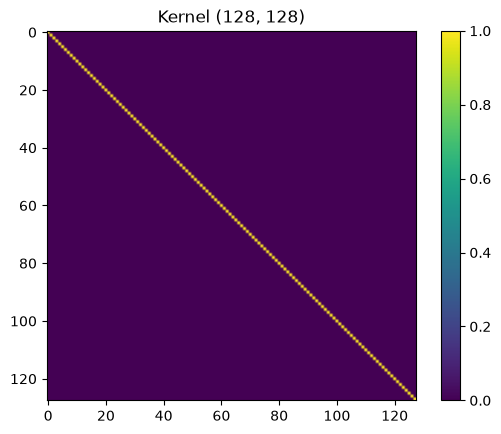

L1 (computational basis) = 0.01819067
L2 (Hadamard basis)      = 0.25626101
Total loss               = 0.13722584
Fidelity                 = 0.00517001
Gradient ((42,)) =  [-0.00185461 -0.0084283   0.0044156  -0.00063893  0.00576138 -0.00669852
  0.00356668 -0.00045758 -0.00223319  0.00783335 -0.00437611 -0.0009889
 -0.00442049 -0.00278989  0.00324614  0.00401814 -0.00128547 -0.00775164
 -0.00569952  0.00764544  0.00849567  0.00466069  0.00251857 -0.00666693
  0.00285957 -0.00412552  0.00846049  0.00465378 -0.00271851 -0.00363714
  0.00910179  0.00782762 -0.00913086  0.00872424 -0.00188738 -0.00236737
  0.00356069  0.00387175 -0.00052161 -0.00569092 -0.01046675  0.00755696]
Epoch 1 - Loss 0.13722583895101922 - Fidelity 0.005170008289972566
L1 (computational basis) = 0.01729078
L2 (Hadamard basis)      = 0.21160658
Total loss               = 0.11444868
Fidelity                 = 0.01143191
Gradient ((42,)) =  [-0.00762922 -0.00197882  0.00803599 -0.00514834  0.00133241 -0.00256852
  0.0

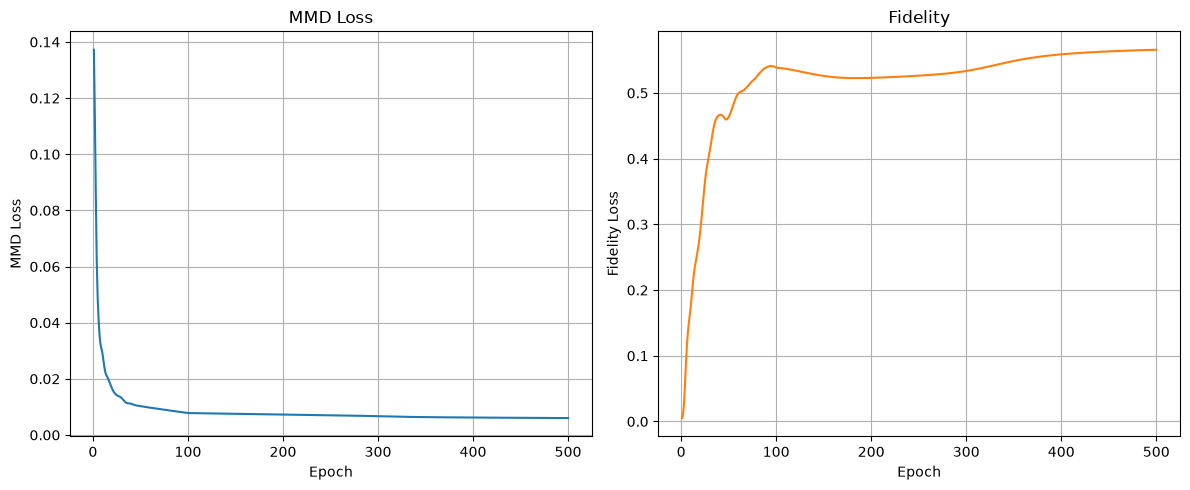


Final statevector: [ 0.1335172 +0.j  0.05981227+0.j  0.09581293+0.j -0.06915718+0.j
  0.02764319+0.j -0.00779707+0.j  0.07590194+0.j  0.02521875+0.j
  0.0845258 +0.j  0.0627443 +0.j  0.0952456 +0.j  0.07262169+0.j
 -0.00809392+0.j  0.02689727+0.j  0.01435446+0.j  0.02822172+0.j
 -0.0288434 +0.j  0.01320139+0.j -0.06496627+0.j -0.1269945 +0.j
  0.11442074+0.j  0.1025368 +0.j  0.04874995+0.j  0.00310199+0.j
  0.04836489+0.j  0.10006761+0.j  0.05781585+0.j -0.05684698+0.j
  0.1461    +0.j  0.11993449+0.j  0.08391833+0.j  0.02641808+0.j
  0.11250994+0.j  0.11478586+0.j  0.07348751+0.j  0.11411583+0.j
 -0.01751836+0.j  0.05566083+0.j  0.00055867+0.j  0.01868503+0.j
  0.11560802+0.j  0.15205692+0.j  0.12846383+0.j  0.11989623+0.j
 -0.01170585+0.j  0.03917171+0.j  0.07418805+0.j  0.09278165+0.j
  0.12033308+0.j  0.09482651+0.j  0.1320641 +0.j  0.03830136+0.j
  0.06322586+0.j -0.06362831+0.j  0.11089186+0.j  0.09138197+0.j
  0.1155926 +0.j  0.10903179+0.j  0.10905234+0.j  0.00943203+0.j
  0.1

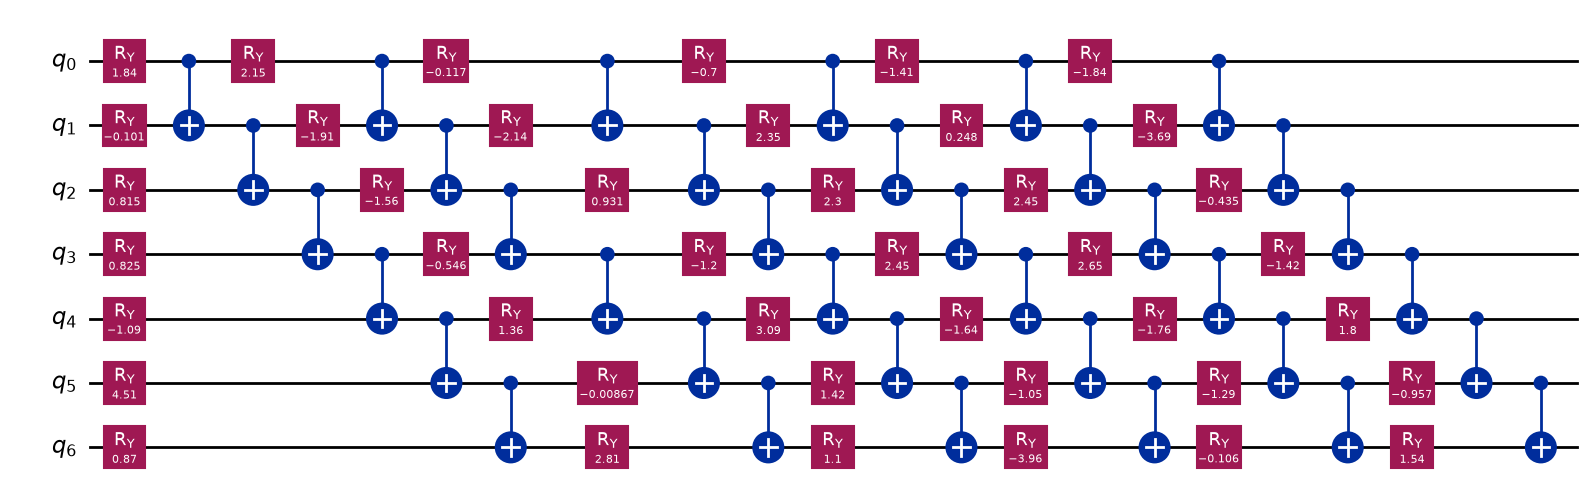


Data =  [[0 0 0 0]
 [1 0 0 0]
 [0 1 0 0]
 [1 1 0 0]
 [0 0 1 0]
 [1 0 1 0]
 [0 1 1 0]
 [1 1 1 0]
 [0 0 0 1]
 [1 0 0 1]
 [0 1 0 1]
 [1 1 0 1]
 [0 0 1 1]
 [1 0 1 1]
 [0 1 1 1]
 [1 1 1 1]]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.56575217


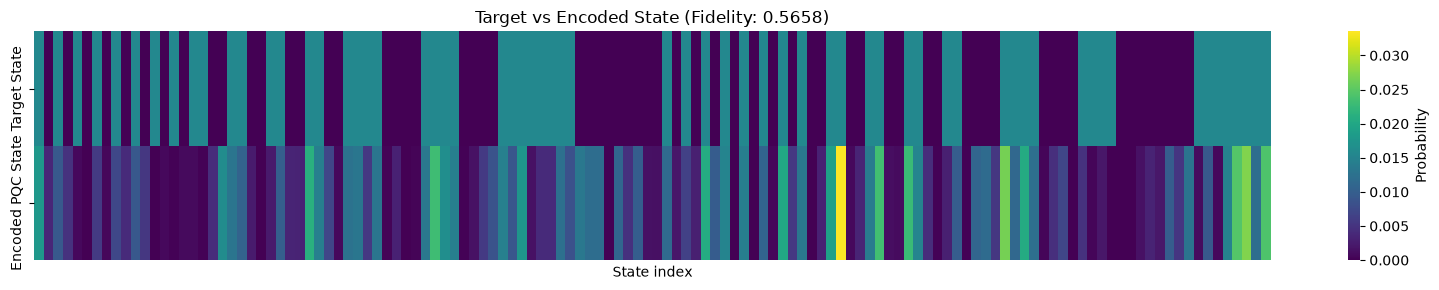

<Axes: title={'center': 'Target vs Encoded State (Fidelity: 0.5658)'}, xlabel='State index'>

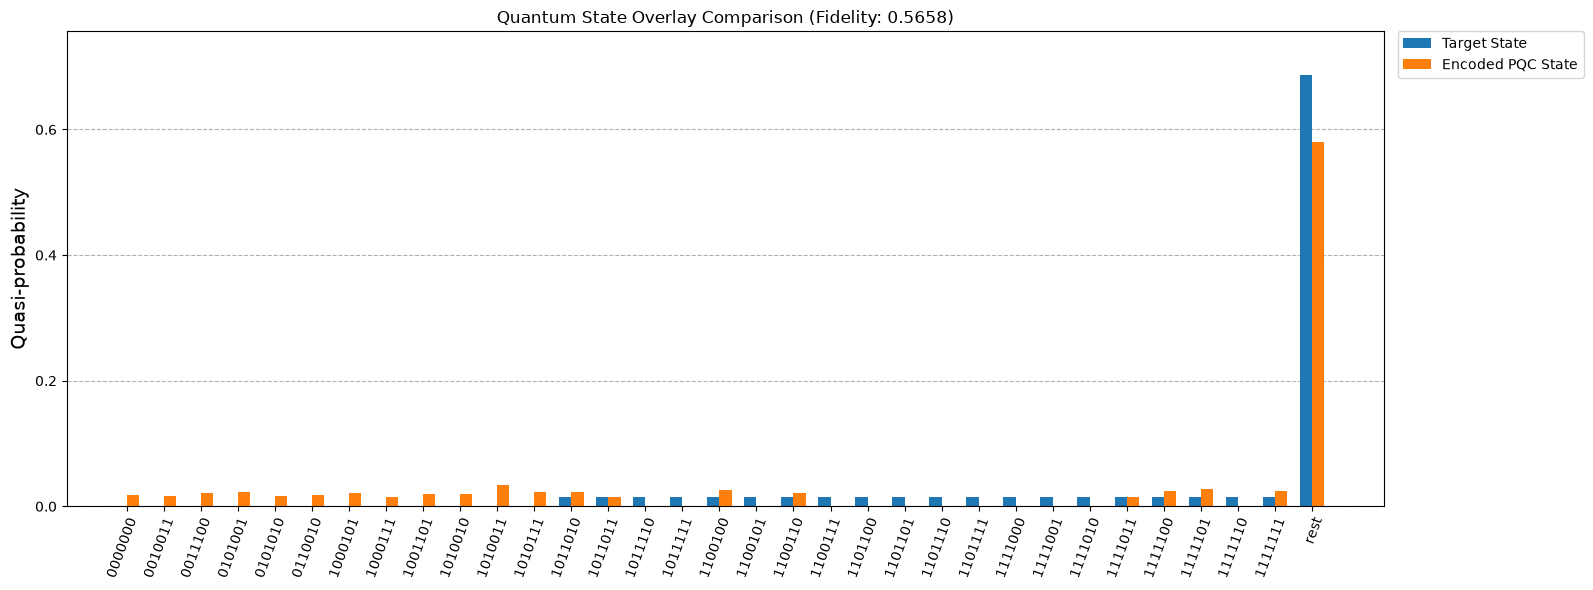

In [9]:
encoder = ApproximateAmplitudeEncoder()
A_parameters = encoder.generate_encoding(dataset, depth=6, epochs=500)


Preparing query target stae....

Number of feature qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 3
Total number of states (total_num_states): 8

Amplitude =  0.5
Value: 1/1; j=0; Index: 4/100; Target amplitude: (0.5+0j)
Value: 1/1; j=1; Index: 5/101; Target amplitude: (0.5+0j)
Value: 0/0; j=2; Index: 2/10; Target amplitude: (0.5+0j)
Value: 0/0; j=3; Index: 3/11; Target amplitude: (0.5+0j)

Target norm: 1.0
Nonzero amplitudes: 4

Number of parameters = 9
Initial parameters = [ 1.25830275 -1.17893516  2.0876499   1.91489093 -0.7069942  -1.32997375
  1.14665307 -2.2635019  -1.88553237]


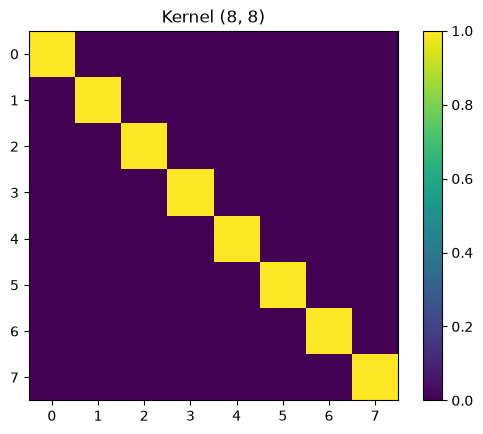

L1 (computational basis) = 0.36873746
L2 (Hadamard basis)      = 0.22396913
Total loss               = 0.29635329
Fidelity                 = 0.14604110
Gradient ((9,)) =  [-0.07985494  0.09692445  0.08061751  0.05206279  0.01477328  0.09900221
 -0.12133707  0.11854621  0.01912259]
Epoch 1 - Loss 0.2963532936928367 - Fidelity 0.14604109952165653
L1 (computational basis) = 0.30462826
L2 (Hadamard basis)      = 0.18960972
Total loss               = 0.24711899
Fidelity                 = 0.10829886
Gradient ((9,)) =  [-0.03295235  0.08352388  0.08841664  0.04618267 -0.05144009  0.05418157
 -0.09103786  0.07967121  0.04768919]
Epoch 2 - Loss 0.2471189867525886 - Fidelity 0.10829885855189102
L1 (computational basis) = 0.25762805
L2 (Hadamard basis)      = 0.17184994
Total loss               = 0.21473899
Fidelity                 = 0.06444902
Gradient ((9,)) =  [-0.02268402  0.06860997  0.05659725  0.04405821 -0.10227049  0.01127483
 -0.07042466  0.0478073   0.05697455]
Epoch 3 - Loss 0.2147389

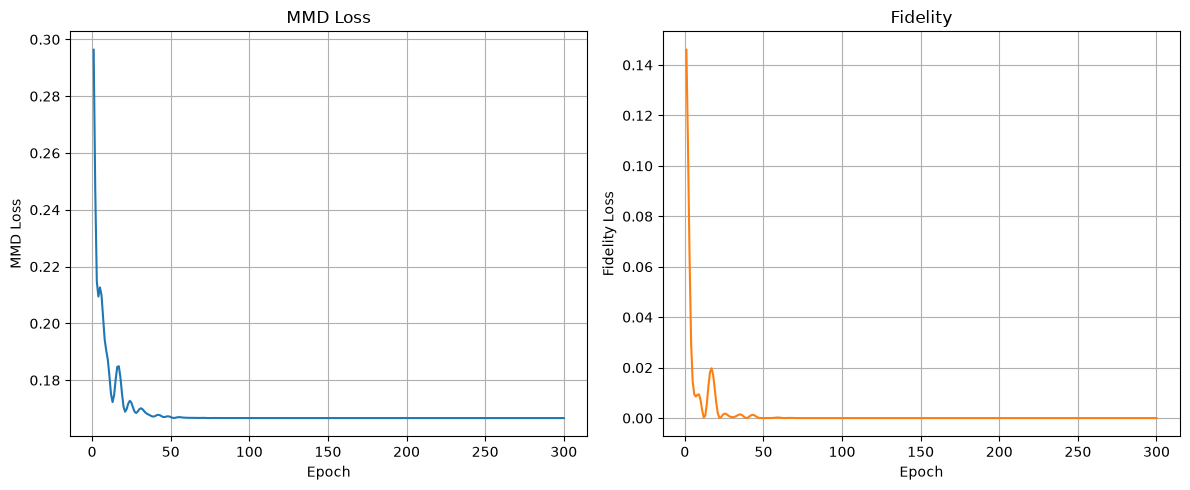


Final statevector: [-0.40794632+0.j -0.40840654+0.j  0.27862474+0.j -0.28835649+0.j
 -0.28966726+0.j  0.29727918+0.j -0.40805328+0.j -0.40891708+0.j]

Training finished
Number of qubits: 3
Circuit depth (layers): 3
Number of parameters: 9
Final MMD loss: 0.16666743


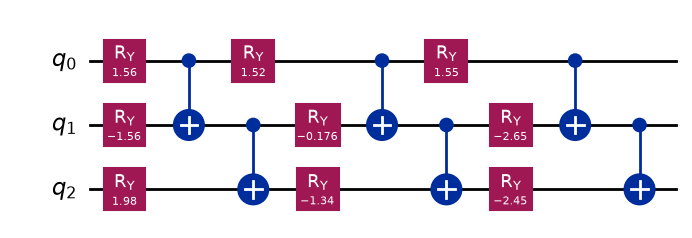


Data =  [1 1 0 0]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.00000112


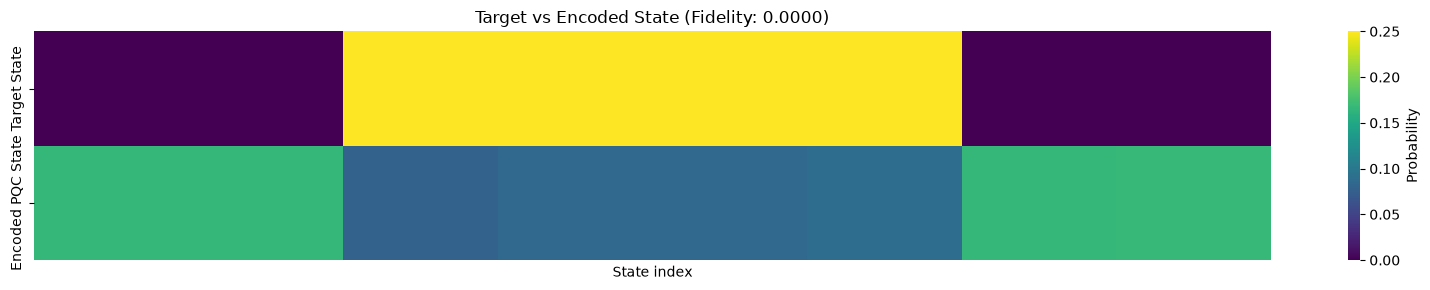

<Axes: title={'center': 'Target vs Encoded State (Fidelity: 0.0000)'}, xlabel='State index'>

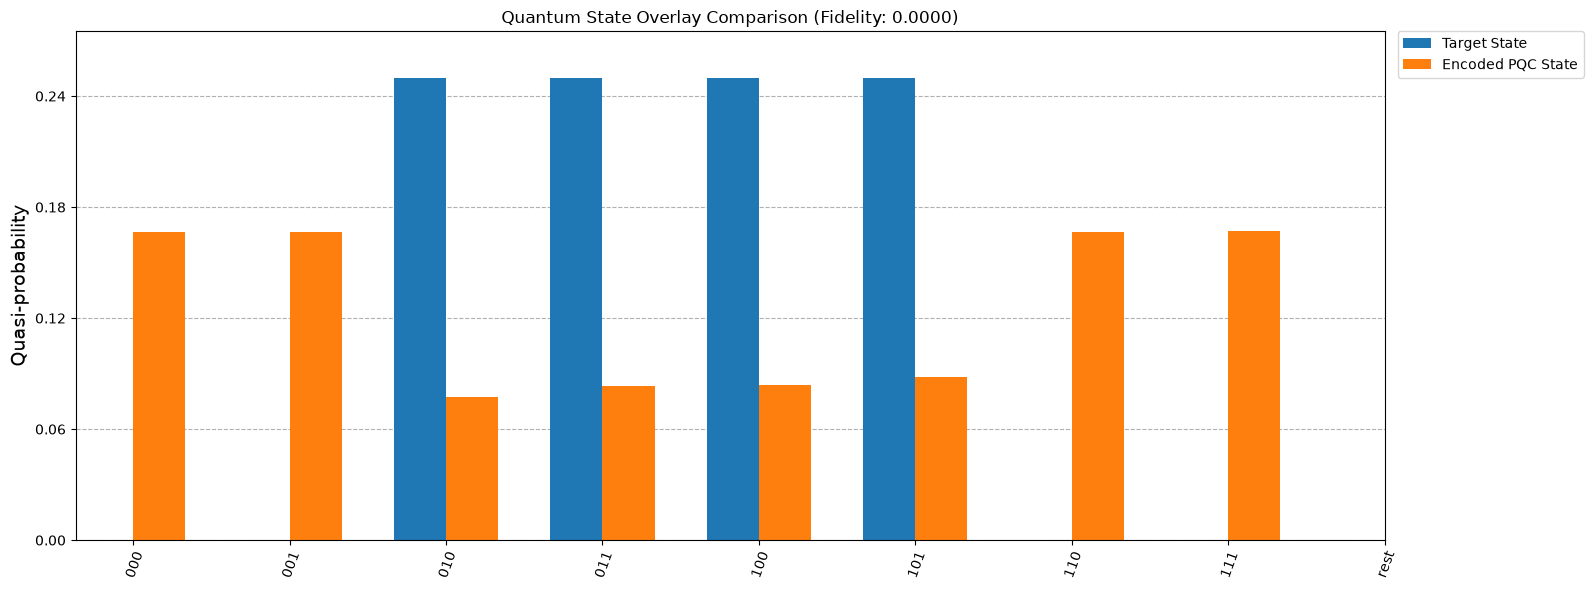

In [10]:
B_parameters = encoder.generate_encoding(query, depth=3, epochs=300)

### **<u>PART 2: UTILIZE GROVER SEARCH FOR IMAGE MATCHING</u>**

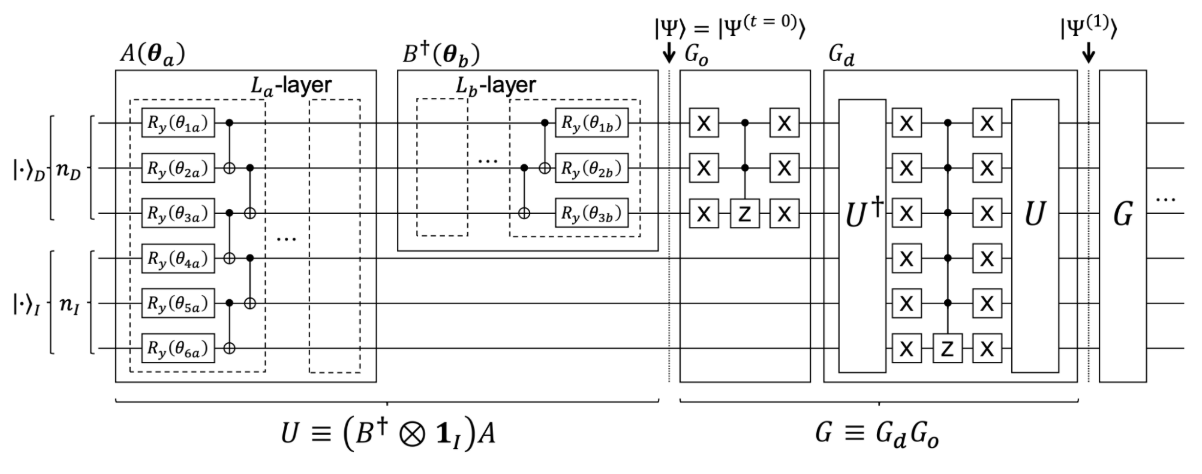

In [11]:
class GroverSearch:
  def pqc(self, parameters, depth, n_qubits):
    qc = QuantumCircuit(n_qubits)
    t = 0

    for _ in range(depth):
        # rotation layer
        for q in range(n_qubits):
            qc.ry(parameters[t], q)
            t += 1

        # entangling layer
        for q in range(n_qubits - 1):
            qc.cx(q, q + 1)

    return qc

  def build_U(self):
    # U = (B† ⊗ I_I) A
    # Qubit order: |data>|index>
    # A encodes the database, B† acts on data qubits only

    qc = QuantumCircuit(self.total_qubits)

    A = self.pqc(self.A_parameters, self.depth_A, self.total_qubits)
    B = self.pqc(self.B_parameters, self.depth_B, self.n_data_q)

    qc.compose(A, qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()

    qc.compose(B.inverse(), qubits=self.data_q, inplace=True)
    qc.barrier()

    return qc

  def phase_flip_zero(self, qc, qubits):
    # Phase flip of |00...0> 
    # X gates convert |00...0> into |11...1>
    # H-MCX-H implements the multi-controlled Z operation to flip the phase of |11...1>

    if len(qubits) == 1:
        qc.x(qubits[0])
        qc.z(qubits[0])
        qc.x(qubits[0])

    else:
        qc.x(qubits)

        qc.h(qubits[-1])
        qc.mcx(qubits[:-1], qubits[-1])
        qc.h(qubits[-1])

        qc.x(qubits)

    return qc

  def oracle(self): # inversion-test oracle Go
    # Go phase-flips the all-zero data state after B†
    # This makes the phase depend on the query-data overlap

    qc = QuantumCircuit(self.total_qubits)

    self.phase_flip_zero(qc, self.data_q)
    qc.barrier()

    return qc

  def diffuser(self): # Gd = U† (phase flip of zero on all qubits) U
    # implements reflection about U|0>

    qc = QuantumCircuit(self.total_qubits)

    U = self.build_U()

    qc.compose(U.inverse(), qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()

    self.phase_flip_zero(qc, list(range(self.total_qubits)))
    qc.barrier()

    qc.compose(U, qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()

    return qc

  def visualize(self, qc, text):
    no_of_locators_on_chart = 10

    state = Statevector.from_instruction(qc)
    probs_dict = state.probabilities_dict(qargs=self.index_q)
    probs_dict = {int(k, 2): v for k, v in probs_dict.items()} # convert binary string keys to integers for better readability
    print(f"{text}: ", probs_dict)

    plot = plot_distribution(probs_dict, bar_labels=False)
    plot.axes[0].xaxis.set_major_locator(plt.MaxNLocator(no_of_locators_on_chart))

    display(plot)

  def run(self, dataset, query,
      A_parameters, B_parameters, depth_A=6, depth_B=3,
      num_of_iter=1, no_of_shots=2000
  ):
    # Dataset and query dimensions
    self.N_I = len(dataset)
    self.N_D = len(dataset[0])
    self.N_Q = len(query)

    # Number of index qubits
    self.n_index_q = math.ceil(math.log2(self.N_I))

    # Number of pixel-position qubits
    self.n_pixel_q = math.ceil(math.log2(self.N_D))

    # Use one consistent intensity range for the database and query.
    # For values 0..255, this gives 8 intensity qubits.
    max_value = max(int(np.max(dataset)), int(np.max(query)))
    self.n_value_q = max(1, math.ceil(math.log2(max_value + 1)))

    # The data register includes pixel-position AND intensity qubits.
    self.n_data_q = self.n_pixel_q + self.n_value_q

    # Total qubits = data register + image-index register
    self.total_qubits = self.n_index_q + self.n_data_q

    # Match the basis-state indexing used in prepare_neqr_dataset_target:
    # index bits are the least-significant bits.
    self.index_q = list(range(self.n_index_q))

    # B† acts on the entire data register, not just pixel-position qubits.
    self.data_q = list(range(self.n_index_q, self.total_qubits))

    # Keep the number of image-index states separate from the
    # dimension of the data register.
    self.padded_N_I = 2**self.n_index_q
    self.padded_N_P = 2**self.n_pixel_q

    print("Index qubits:", self.index_q)
    print("Data qubits:", self.data_q)
    print("Pixel-position qubits:", self.n_pixel_q)
    print("Intensity qubits:", self.n_value_q)
    print("Total qubits:", self.total_qubits)

    # pad the dataset and query to the power of 2

    padded_dataset = np.zeros((self.padded_N_I, self.padded_N_P))
    padded_dataset[:self.N_I, :self.N_D] = dataset
    dataset = padded_dataset

    padded_query = np.zeros(self.padded_N_P)
    padded_query[:self.N_Q] = query 
    query = padded_query

    # A and B parameters

    self.A_parameters = np.asarray(A_parameters)
    self.B_parameters = np.asarray(B_parameters)
    self.depth_A = depth_A
    self.depth_B = depth_B

    print("N = ", self.N_I)
    print("Index qubits = ", self.index_q)
    print("Data qubits = ", self.data_q)
    print("Total no of qubits = ", self.total_qubits)

    # num_of_iter = max(1, round(((math.pi / 4) * math.sqrt(self.N_I)) - 0.5))
    # print("\nGrover iterations: ", num_of_iter)

    index_qubits = QuantumRegister(self.n_index_q, name="index")
    data_qubits = QuantumRegister(self.n_data_q, name="data")
    value_qubits = QuantumRegister(self.n_value_q, name="value")
    qc = QuantumCircuit(index_qubits, data_qubits, value_qubits)
    
    qc = self.build_U()
    self.visualize(qc, "Encoded state U|Psi(0)>")

    for iteration in range(num_of_iter):
        print(f"\nGROVER ITERATION {iteration + 1}")

        print("\nOracle: ")
        oracle_circuit = self.oracle()
        qc.compose(oracle_circuit, qubits=list(range(self.total_qubits)), inplace=True)
        self.visualize(qc, "Oracle output")

        print("\nDiffuser: ")
        diffuser_circuit = self.diffuser()
        qc.compose(diffuser_circuit, qubits=list(range(self.total_qubits)), inplace=True)
        self.visualize(qc, "Diffuser output")

    print("\nFINAL MEASUREMENT")

    self.qc = qc.copy()

    classical_register = ClassicalRegister(self.n_index_q, name="index_result")
    self.qc.add_register(classical_register)

    self.qc.measure(self.index_q, classical_register)

    simulator = AerSimulator()
    compiled = transpile(self.qc, simulator)

    result = simulator.run(compiled, shots=no_of_shots).result()
    counts = result.get_counts()

    print(f"\nIndex measurement results for ({no_of_shots}) shots:")
    print(counts)

    self.qc = qc.copy()

  def draw_circuit(self):
    display(self.qc.draw("mpl"))

  def analysis(self):
    print("REGISTER ANALYSIS")

    print("Dataset size (N):", self.N_I)
    print("Index qubits:", len(self.index_q))
    print("Data qubits:", len(self.data_q))
    print("Total qubits:", self.qc.num_qubits)
    print("Classical bits:", self.qc.num_clbits)

    print("\nCIRCUIT ANALYSIS")

    print("Circuit width:", self.qc.width())
    print("Circuit size:", self.qc.size())
    print("Circuit depth/layers:", self.qc.depth())

    print("\nOPERATION COUNT")
    print(self.qc.count_ops())

  
  def visualize(self, qc, text):
    no_of_locators_on_chart = 10

    state = Statevector.from_instruction(qc)

    # Display the complete quantum state in LaTeX notation
    print(f"\n{text} - Quantum State:")
    display(state.draw('latex'))

    probs_dict = state.probabilities_dict(qargs=self.index_q)
    probs_dict = {int(k, 2): v for k, v in probs_dict.items()} # convert binary string keys to integers for better readability

    plot = plot_distribution(probs_dict, bar_labels=False)
    plot.axes[0].xaxis.set_major_locator(plt.MaxNLocator(no_of_locators_on_chart))

    display(plot)


Index qubits: [0, 1, 2, 3]
Data qubits: [4, 5, 6]
Pixel-position qubits: 2
Intensity qubits: 1
Total qubits: 7
N =  16
Index qubits =  [0, 1, 2, 3]
Data qubits =  [4, 5, 6]
Total no of qubits =  7

Encoded state U|Psi(0)> - Quantum State:


<IPython.core.display.Latex object>

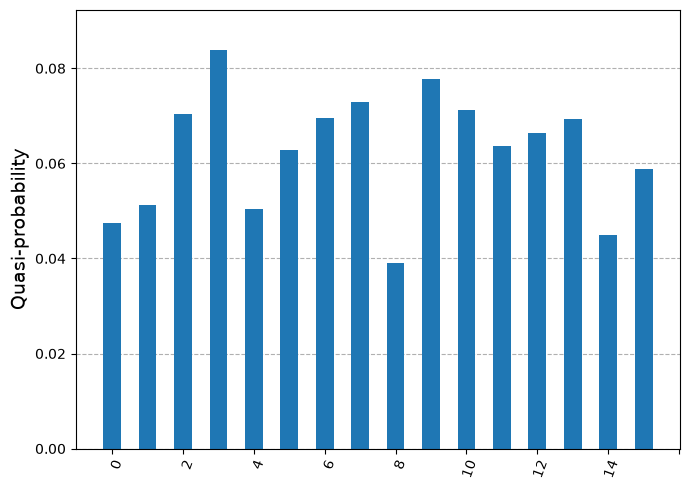


GROVER ITERATION 1

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

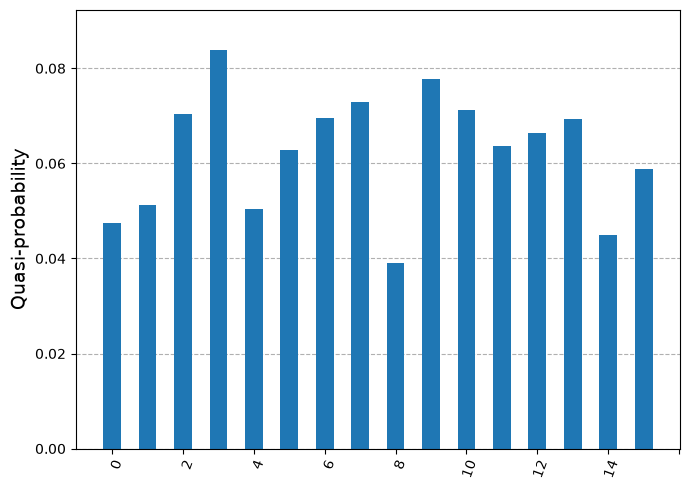


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

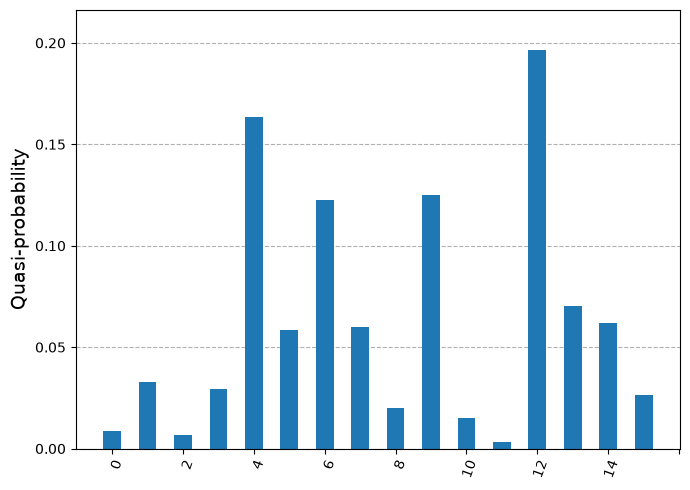


GROVER ITERATION 2

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

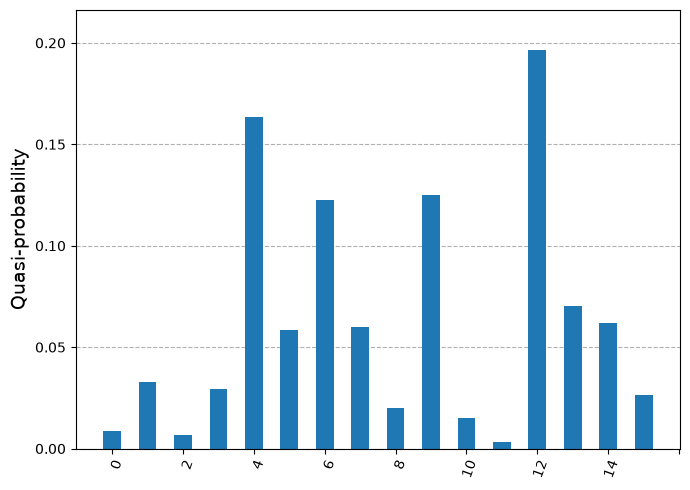


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

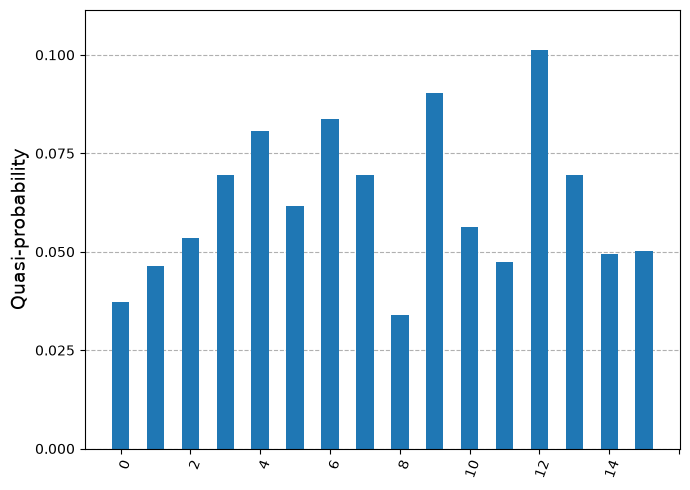


GROVER ITERATION 3

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

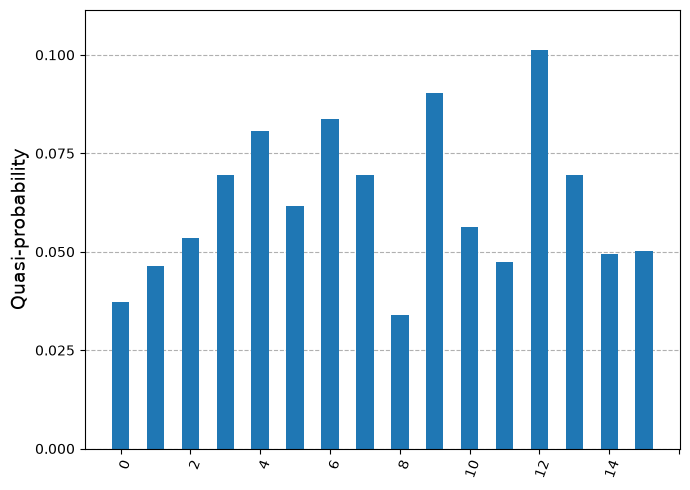


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

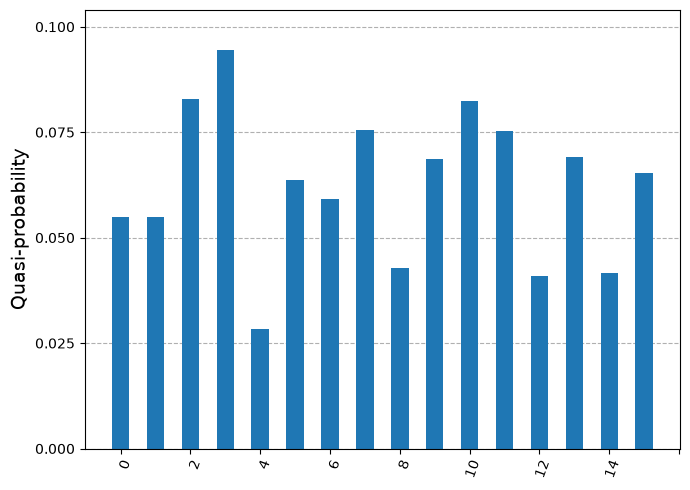


GROVER ITERATION 4

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

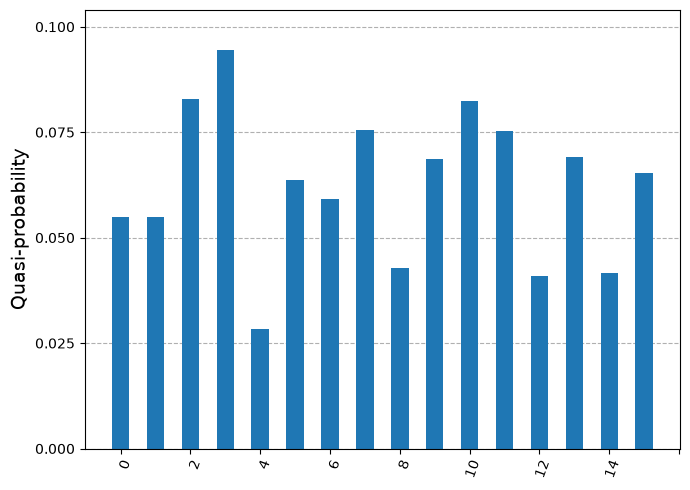


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

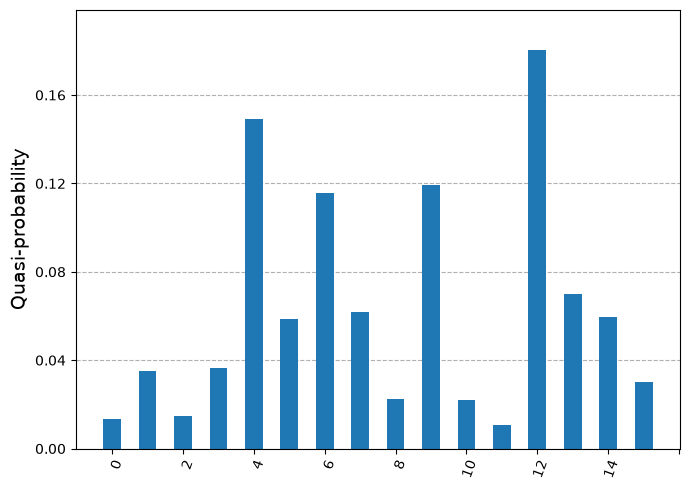


GROVER ITERATION 5

Oracle: 

Oracle output - Quantum State:


<IPython.core.display.Latex object>

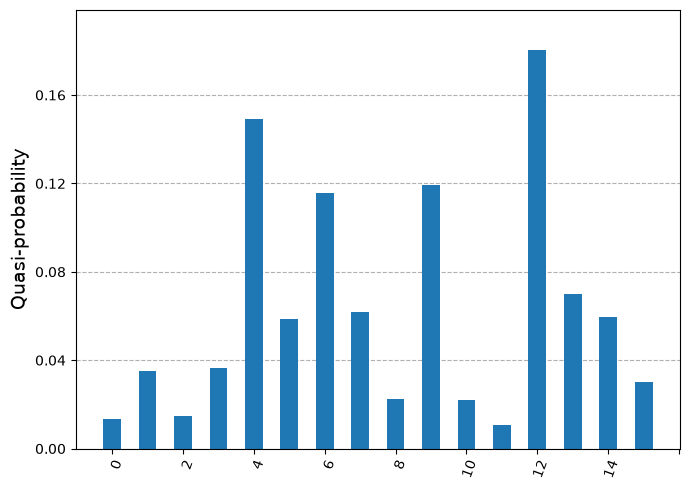


Diffuser: 

Diffuser output - Quantum State:


<IPython.core.display.Latex object>

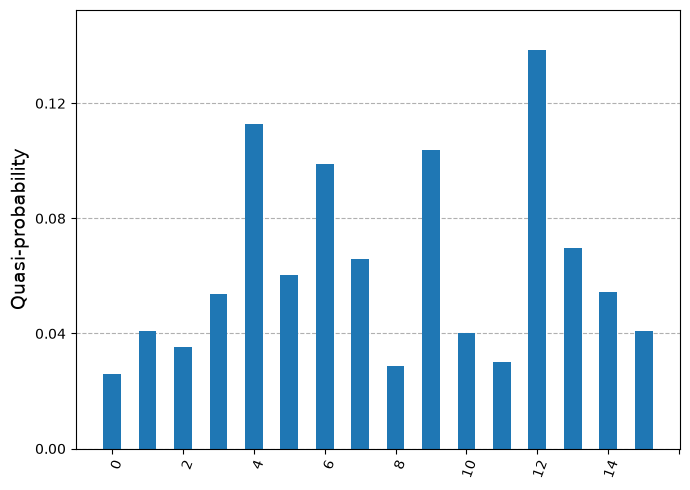


FINAL MEASUREMENT

Index measurement results for (2000) shots:
{'1010': 97, '1011': 56, '0000': 44, '0010': 59, '0100': 200, '1100': 295, '1000': 58, '1110': 98, '1001': 194, '1101': 155, '1111': 88, '0111': 149, '0101': 126, '0011': 122, '0001': 74, '0110': 185}


In [12]:
GS = GroverSearch()

GS.run(dataset=dataset, query=query,
    A_parameters=A_parameters, B_parameters=B_parameters,
    depth_A=6, depth_B=3,
    num_of_iter=5
)

In [13]:
query_index

3

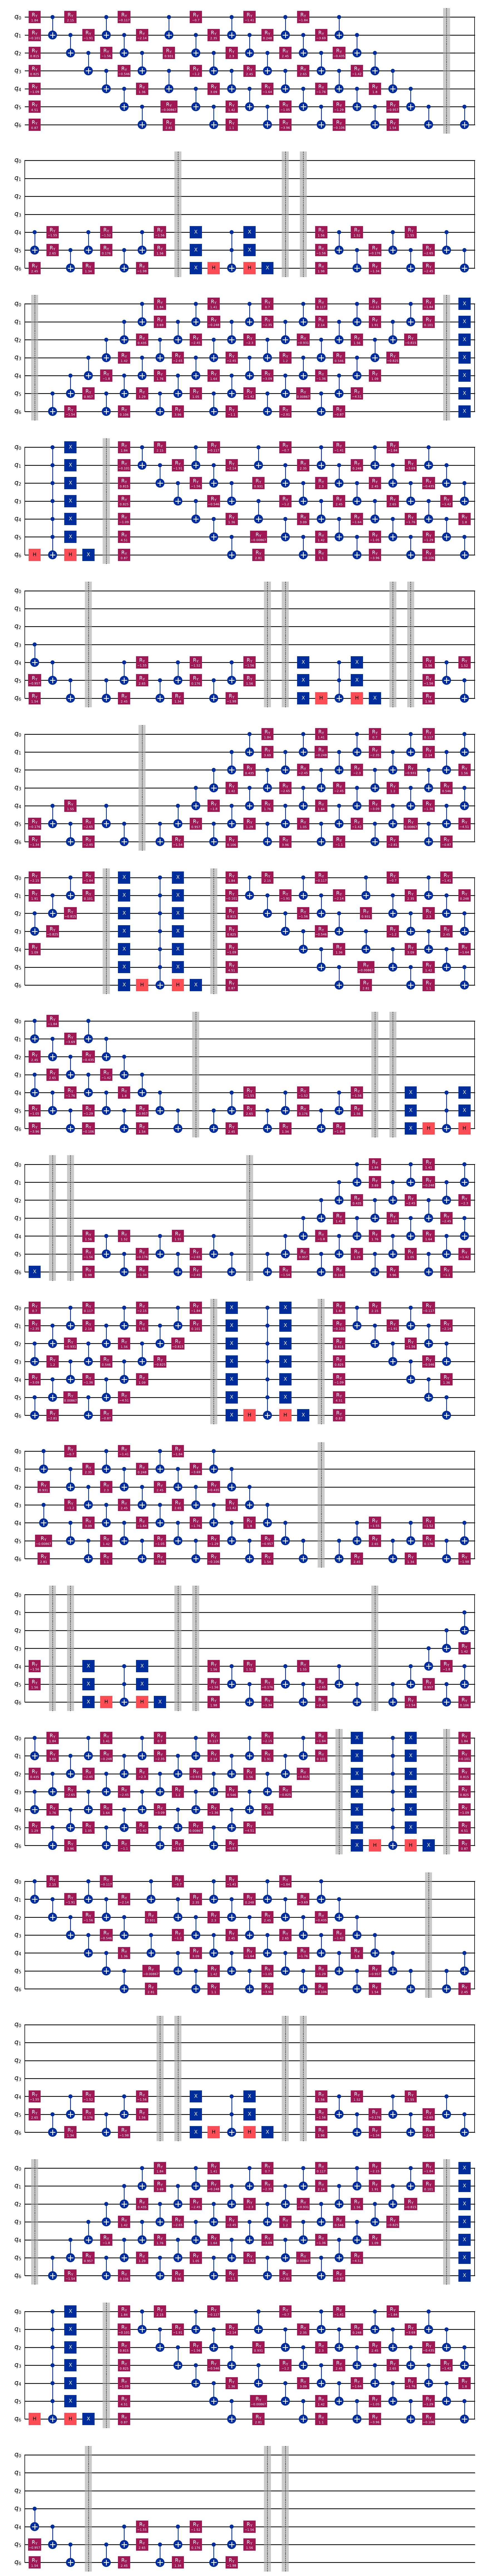

In [14]:
GS.draw_circuit()

In [15]:
GS.analysis()

REGISTER ANALYSIS
Dataset size (N): 16
Index qubits: 4
Data qubits: 3
Total qubits: 7
Classical bits: 0

CIRCUIT ANALYSIS
Circuit width: 7
Circuit size: 1153
Circuit depth/layers: 391

OPERATION COUNT
OrderedDict({'ry': 561, 'cx': 462, 'x': 100, 'barrier': 42, 'h': 20, 'ccx': 5, 'mcx': 5})
